First, I imported popular Python libraries such as  pandas, matplotlib, etc.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Now, CSV data file namely products.csv is imported

In [ ]:
#import data file
df = pd.read_csv("/content/products_data.csv")
df

,Name,Current Price,Previous Price,Price Per Each,Category,Product ID,Product URL,Amount,Units
0,English Cucumber,1.99,1.99,$1.99/1ea,Fresh Vegetables,20070132001_EA,https://www.realcanadiansuperstore.ca/english-...,1,ea
1,Green Onion,1.29,1.29,$1.29/1ea,Fresh Vegetables,20107500001_EA,https://www.realcanadiansuperstore.ca/green-on...,1,bunch
2,"Bi-Colour Corn, Corn on the Cob",0.99,0.99,$0.99/1ea,Fresh Vegetables,20131170001_EA,https://www.realcanadiansuperstore.ca/bi-colou...,1,ea
3,"Romaine Heart, 3 Pack",6.00,6.00,$2.00/1ea,Fresh Vegetables,20067389001_EA,https://www.realcanadiansuperstore.ca/romaine-...,3,pack
4,Red Peppers,2.38,2.38,$9.90/1kg,Fresh Vegetables,20007535001_KG,https://www.realcanadiansuperstore.ca/red-pepp...,1,ea
...,...,...,...,...,...,...,...,...,...
17254,Beef Sausage Rolls,8.79,8.79,$1.40/100g,Quiches & Pies,21116219_EA,https://www.realcanadiansuperstore.ca/beef-sau...,630,g
17255,Creamy Chicken and Vegetable Pot Pie,8.00,8.00,"$1,600.00/100g",Quiches & Pies,21401776_EA,https://www.realcanadiansuperstore.ca/creamy-c...,500,g
17256,Quiche Florentine,8.00,8.00,$1.60/100g,Quiches & Pies,21401761_EA,https://www.realcanadiansuperstore.ca/quiche-f...,500,g
17257,Green Tea,2.29,2.29,$0.48/100ml,Beverages,20923222_EA,https://www.realcanadiansuperstore.ca/green-te...,473,ml


data.info() method is used in pandas to get information about dataframe

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17259 entries, 0 to 17258
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Name            17259 non-null  object 
 1   Current Price   17258 non-null  float64
 2   Previous Price  17258 non-null  float64
 3   Price Per Each  0 non-null      float64
 4   Category        17259 non-null  object 
 5   Product ID      17259 non-null  object 
 6   Product URL     17259 non-null  object 
 7   Amount          16375 non-null  float64
 8   Units           0 non-null      float64
 9   Price Change    17258 non-null  float64
dtypes: float64(6), object(4)
memory usage: 1.3+ MB


Now,  relevant columns are converted to numeric types

In [ ]:
# Convert relevant columns to numeric types
numeric_columns = ['Current Price', 'Previous Price', 'Price Per Each', 'Amount', 'Units']
data[numeric_columns] = data[numeric_columns].apply(pd.to_numeric, errors='coerce')


In [ ]:
# Descriptive Statistics
summary_stats = data.describe()

Using a dataset, I conducts exploratory data analysis. Using the plot() method, it generates a box plot for the dataset's "Current Price" and "Previous Price" columns.

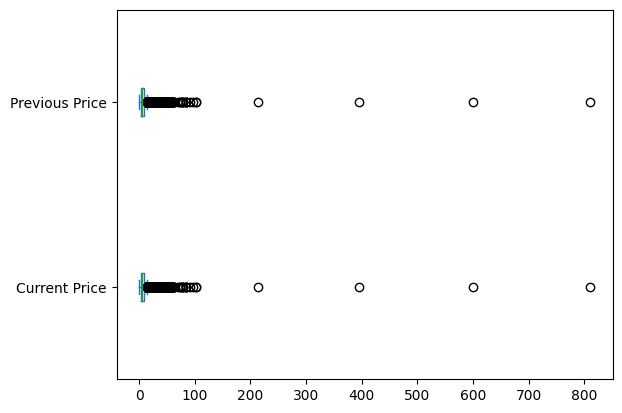

In [ ]:
# Exploratory Data Analysis (EDA)
category_counts = data['Category'].value_counts()
price_distribution = data[['Current Price', 'Previous Price']].plot(kind='box', vert=False)

In this code, computes and filters data according to changes in price within a dataset.

In [ ]:
# Price Change Analysis
price_change = data['Current Price'] - data['Previous Price']
data['Price Change'] = price_change
significant_price_changes = data[data['Price Change'].abs() > 0.1 * data['Current Price']]


It generates a bar plot to show how the categories in a dataset are distributed.

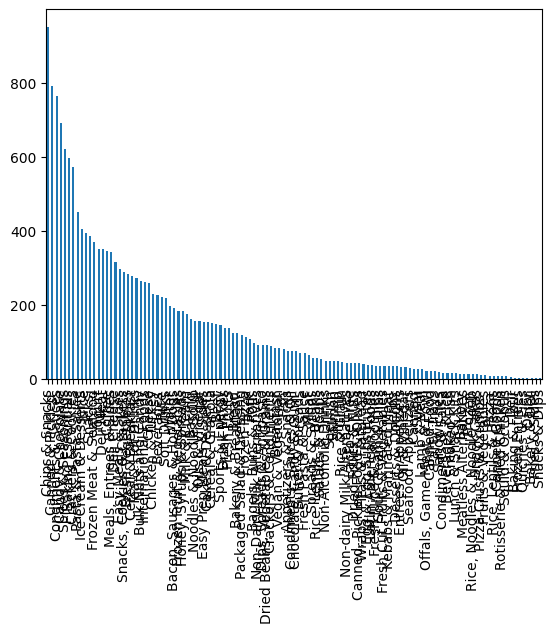

In [ ]:
# Product Categorization
category_distribution = data['Category'].value_counts().plot(kind='bar')


In this section, it calculates the number of unique URLs in the 'Product URL'.italicized text

In [ ]:
# URL Analysis
unique_urls = data['Product URL'].nunique()


Here, it calculates the distribution of values in the 'Units' column.

In [ ]:
# Unit Analysis
unit_distribution = data['Units'].value_counts()


Here, it creates a scatter plot to visualize the relationship between the 'Current Price' and 'Units' columns of a dataset.

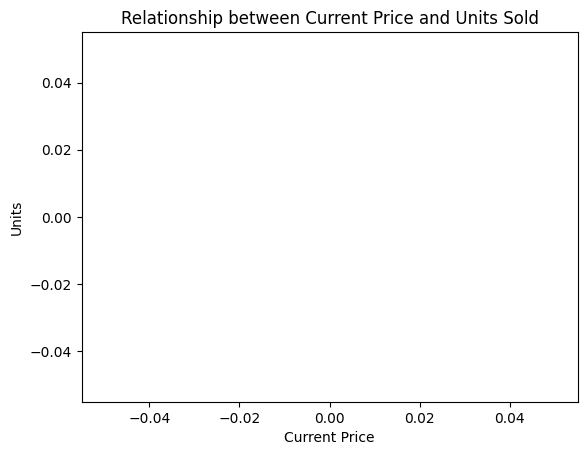

In [ ]:
# Data Visualization
plt.scatter(data['Current Price'], data['Units'])
plt.xlabel('Current Price')
plt.ylabel('Units')
plt.title('Relationship between Current Price and Units Sold')
plt.show()

Here, I identifies outliers in numeric columns of a dataset based on a threshold of three times the standard deviation from the mean. The lambda function compares each value in the column to its mean value and checks if the absolute difference is greater than three times the standard deviation of the column.

In [ ]:
# Identify Outliers
outliers = data[numeric_columns].apply(lambda x: (x - x.mean()).abs() > 3 * x.std())


Show Summary Statistics

In [ ]:
# Displaying results
print("Summary Statistics:")

Summary Statistics:


In [ ]:
print(summary_stats)

       Current Price  Previous Price  Price Per Each        Amount  Units  \
count   17258.000000    17258.000000             0.0  16375.000000    0.0   
mean        6.948198        7.011918             NaN    295.072220    NaN   
std        10.460156       10.467248             NaN    270.196103    NaN   
min         0.010000        0.180000             NaN      0.077000    NaN   
25%         3.490000        3.490000             NaN     64.000000    NaN   
50%         4.990000        5.000000             NaN    250.000000    NaN   
75%         7.990000        7.990000             NaN    454.000000    NaN   
max       809.990000      809.990000             NaN   5000.000000    NaN   

       Price Change  
count  17258.000000  
mean      -0.063720  
std        0.346013  
min       -6.300000  
25%        0.000000  
50%        0.000000  
75%        0.000000  
max        0.000000  


Print Category Distribution

In [ ]:
print("\nCategory Distribution:")
print(category_counts)


Category Distribution:
Chips & Snacks         951
Canned & Pickled       792
Condiments & Sauces    764
Candy & Chocolate      690
Spices & Seasonings    620
                      ... 
Quiches & Pies           3
Dairy                    2
Bakery & Deli            1
Fries & Sides            1
Snacks & Dips            1
Name: Category, Length: 118, dtype: int64


Display Significant Price Changes

In [ ]:
print("\nSignificant Price Changes:")
print(significant_price_changes)


Significant Price Changes:
                                                    Name  Current Price  \
11                                              Zucchini           0.92   
15                                         Roma Tomatoes           0.39   
16                                       Broccoli Crowns           1.65   
20     Naturally Imperfect Mixed Sweet Peppers 2.5lb Bag           5.00   
41                                  Yellow Mini Potatoes           2.99   
...                                                  ...            ...   
17056                   Rainbow Cheese Tortellini, Large           6.99   
17075                                  Tortellini, Beef            6.99   
17095                                          Linguine            6.99   
17104                         Ravioli, Cheese & Spinach            6.99   
17197                                Chicken Noodle Soup           6.00   

       Previous Price  Price Per Each             Category      Product

Display Unique URLs

In [ ]:
print("\nUnique URLs:")
print(unique_urls)


Unique URLs:
14423


Display Unit Distribution

In [ ]:
print("\nUnit Distribution:")
print(unit_distribution)


Unit Distribution:
Series([], Name: Units, dtype: int64)


Print Descriptive Statistics

In [ ]:
# Descriptive Statistics
print("\nDescriptive Statistics:")
print(data.describe())


Descriptive Statistics:
       Current Price  Previous Price  Price Per Each        Amount  Units  \
count   17258.000000    17258.000000             0.0  16375.000000    0.0   
mean        6.948198        7.011918             NaN    295.072220    NaN   
std        10.460156       10.467248             NaN    270.196103    NaN   
min         0.010000        0.180000             NaN      0.077000    NaN   
25%         3.490000        3.490000             NaN     64.000000    NaN   
50%         4.990000        5.000000             NaN    250.000000    NaN   
75%         7.990000        7.990000             NaN    454.000000    NaN   
max       809.990000      809.990000             NaN   5000.000000    NaN   

       Price Change  
count  17258.000000  
mean      -0.063720  
std        0.346013  
min       -6.300000  
25%        0.000000  
50%        0.000000  
75%        0.000000  
max        0.000000  


Explore unique values in categorical columns

In [ ]:
# Explore unique values in categorical columns
print("\nUnique Categories:")
print(data['Category'].unique())


Unique Categories:
['Fresh Vegetables' 'Fresh Fruits' 'Packaged Salad & Dressing' 'Herbs'
 'Fresh Cut Fruits & Vegetables' 'Dried Fruits & Nuts'
 'Fresh Juice & Smoothies' 'Milk & Cream' 'Egg & Egg Substitutes'
 'Butter & Spreads' 'Cheese' 'Yogurt' 'Desserts & Doughs'
 'Sour Cream & Dips' 'Lactose Free' 'Non-Dairy Milk Alternatives'
 'Canned & Pickled ' 'Baking Essentials' 'Pasta & Pasta Sauce'
 'Easy Meals & Sides' 'Cereal & Breakfast' 'Honey, Syrups & Spreads'
 'Rice' 'Oils & Vinegar' 'Condiments & Sauces' 'Spices & Seasonings'
 'Dried Beans, Vegetables & Grains' 'Bulk Nuts and Candy'
 'International Foods' 'Rice & Grain' 'Noodles & Noodle Soup'
 'Snacks, Cookies & Crackers' 'Condiments, Sauces & Oil'
 'Rice, Lentils, & Beans' 'Bakery' 'Rice, Lentils & Beans'
 'Baking & Flour' 'Meat' 'Deli' 'Dairy' 'Frozen Entrees'
 'Canned, Pickled Food & Olives' 'Frozen' 'Rice, Noodles & Noodle Soup'
 'Canned Food' 'Condiments & Salsa' 'Fruits & Vegetables'
 'Latin American Foods' 'Canned Goods' '

In this code, it allows visualizing the distribution and potential outliers in the numeric columns of the dataset, providing insights into the range and variability of the data.

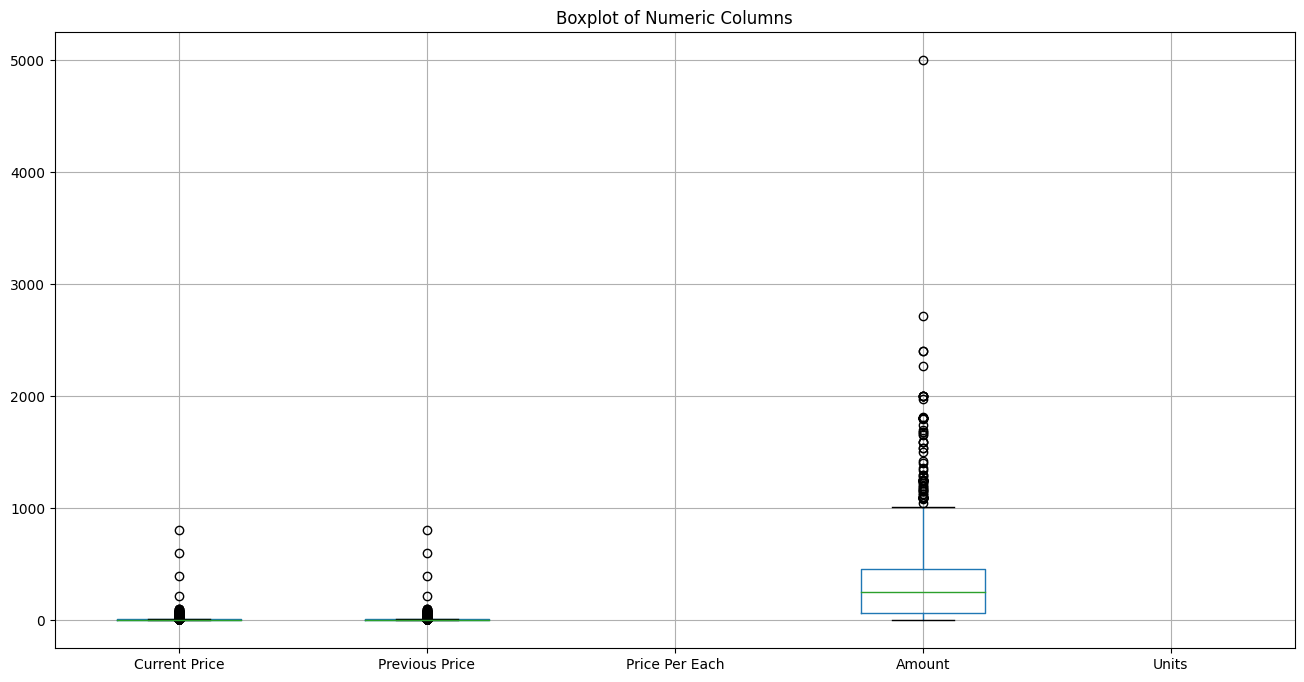

In [ ]:
# Visualize the distribution of numeric columns
plt.figure(figsize=(16, 8))
data[numeric_columns].boxplot()
plt.title('Boxplot of Numeric Columns')
plt.show()

Here, It helps visualize the relationships between different numeric columns in the dataset, providing insights into correlations, distributions, and potential patterns among the variables. It creates a pair plot for the numeric columns of a dataset using the seaborn library.

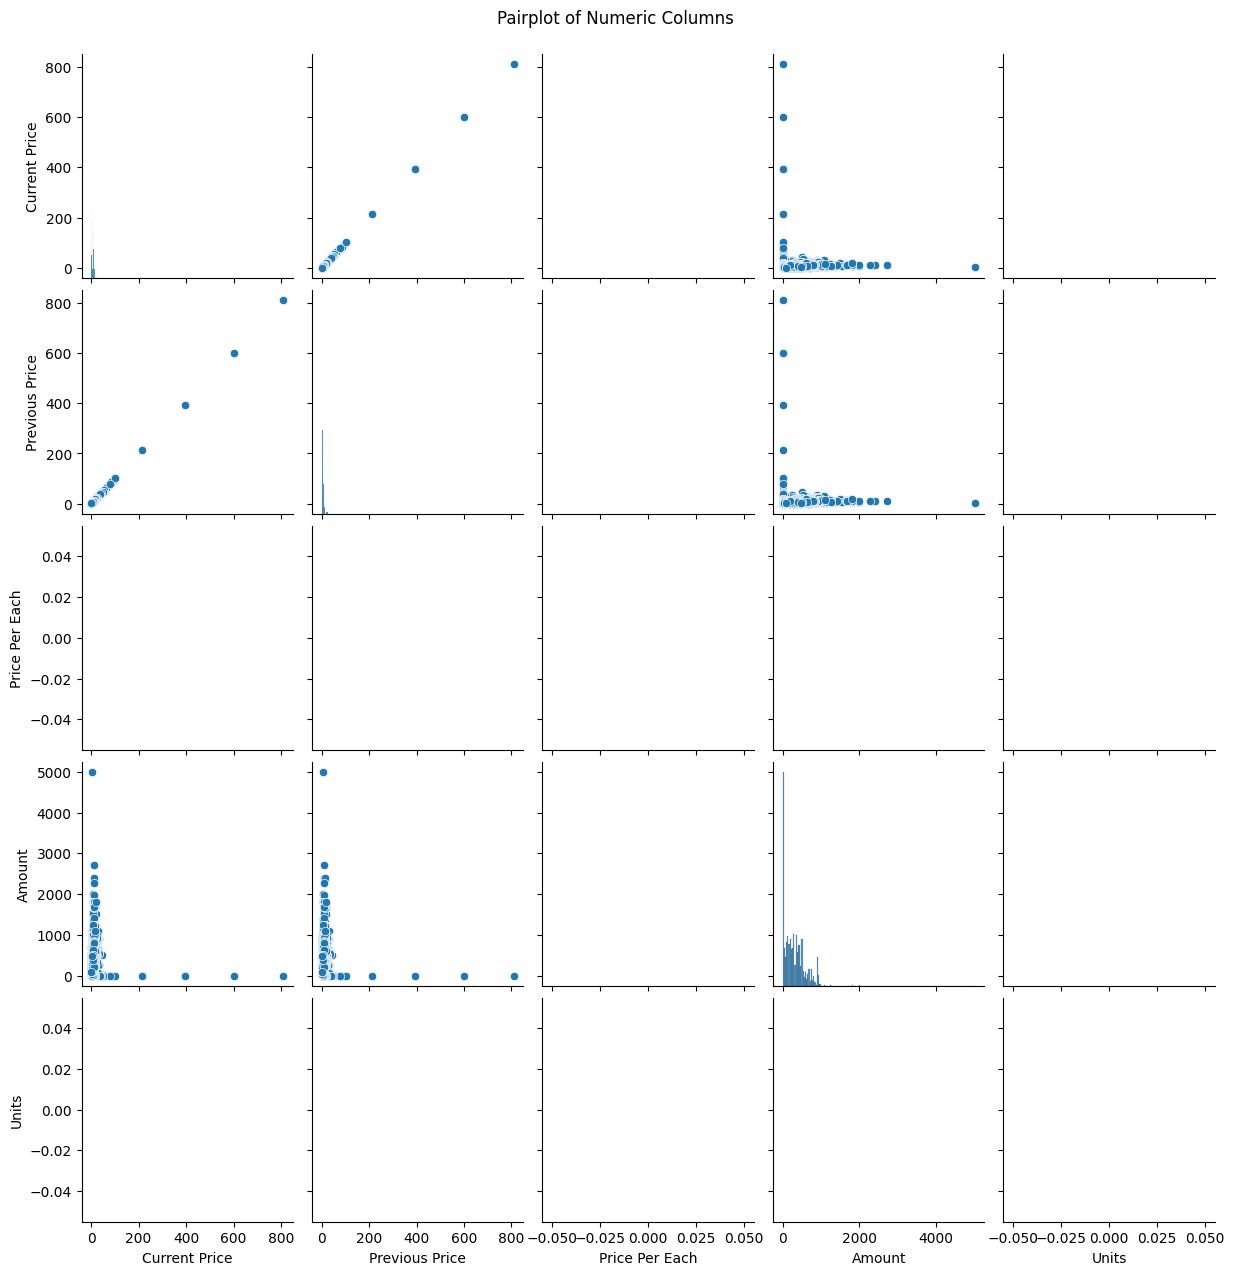

In [ ]:
# Explore the relationship between numerical variables
sns.pairplot(data[numeric_columns])
plt.suptitle('Pairplot of Numeric Columns', y=1.02)
plt.show()

In this code, I created a correlation matrix and displays it as a heatmap using the seaborn library. It provides information on the direction and strength of the links between variables by visualizing the correlation between the dataset's various numeric columns.

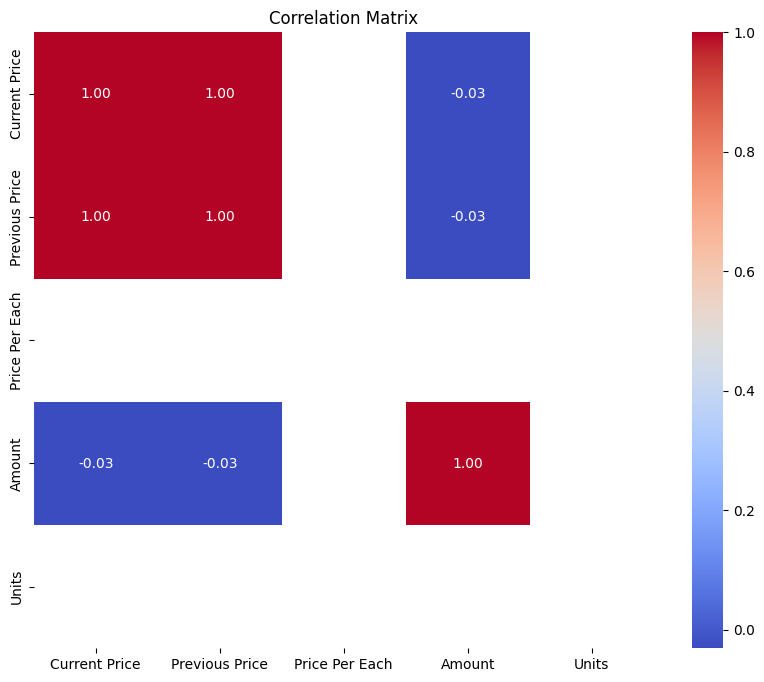

In [ ]:
# Correlation matrix
correlation_matrix = data[numeric_columns].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

It creates a histogram to visualize the distribution of the 'Units' column. This code allows visualizing the distribution of the 'Units' column in the dataset, providing insights into the frequency and range of units sold.

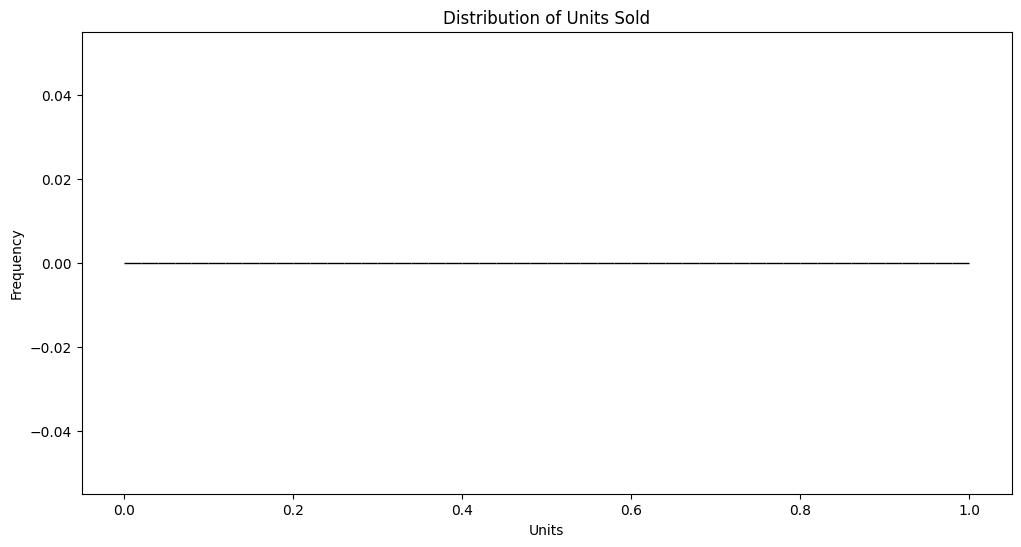

In [ ]:
# Explore the distribution of units
plt.figure(figsize=(12, 6))
sns.histplot(data['Units'].astype(float), bins=50, kde=True)
plt.title('Distribution of Units Sold')
plt.xlabel('Units')
plt.ylabel('Frequency')
plt.show()

Here, I identify and visualize outliers. It also gives insights into the range and variability of the data and aids in the identification of any potential outliers by allowing the distribution and prospective outliers to be seen in the dataset's numerical columns.

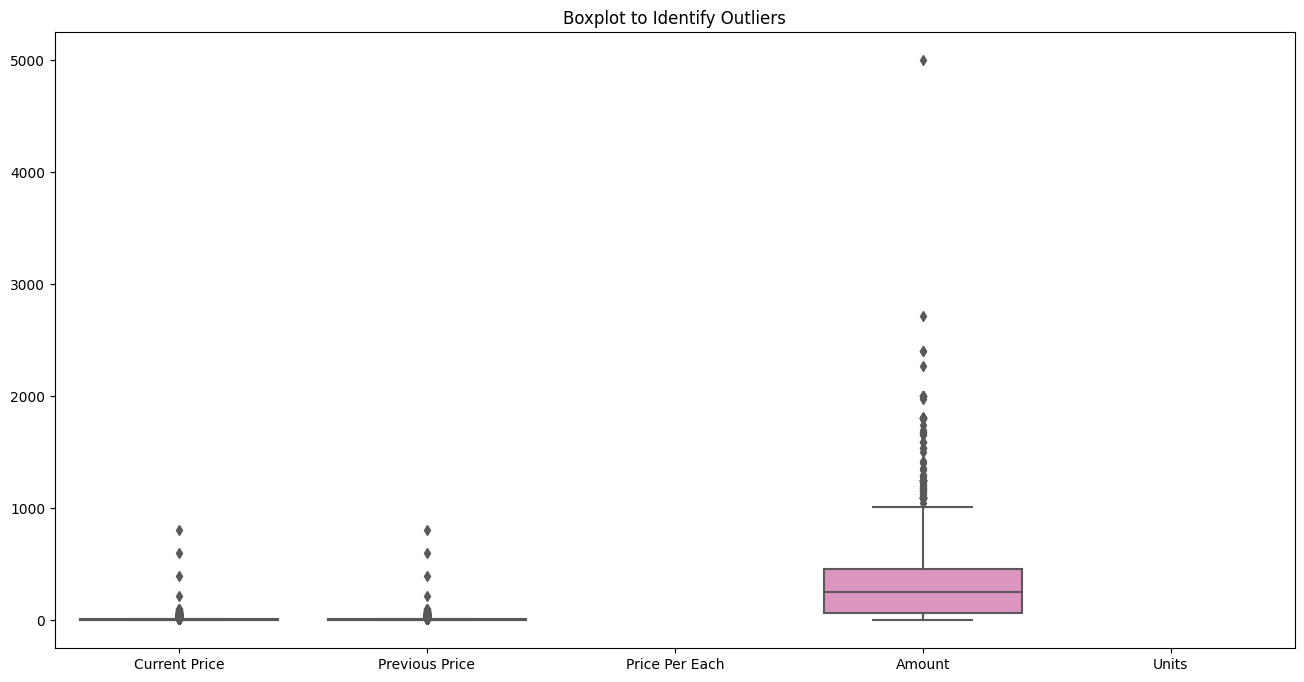

In [ ]:
# Identify and visualize outliers
plt.figure(figsize=(16, 8))
sns.boxplot(data=data[numeric_columns], palette='Set2')
plt.title('Boxplot to Identify Outliers')
plt.show()

In [ ]:
# Convert relevant columns to numeric types
numeric_columns = ['Current Price', 'Previous Price', 'Price Per Each', 'Amount', 'Units']
data[numeric_columns] = data[numeric_columns].apply(pd.to_numeric, errors='coerce')


In [ ]:
# Calculate price changes
data['Price Change'] = data['Current Price'] - data['Previous Price']


In this, A histogram is produced by the provided code to show the distribution of price changes in a dataset. With the help of this code, it is possible to see how prices vary and gain insight into the frequency and scope of price fluctuations within the dataset.

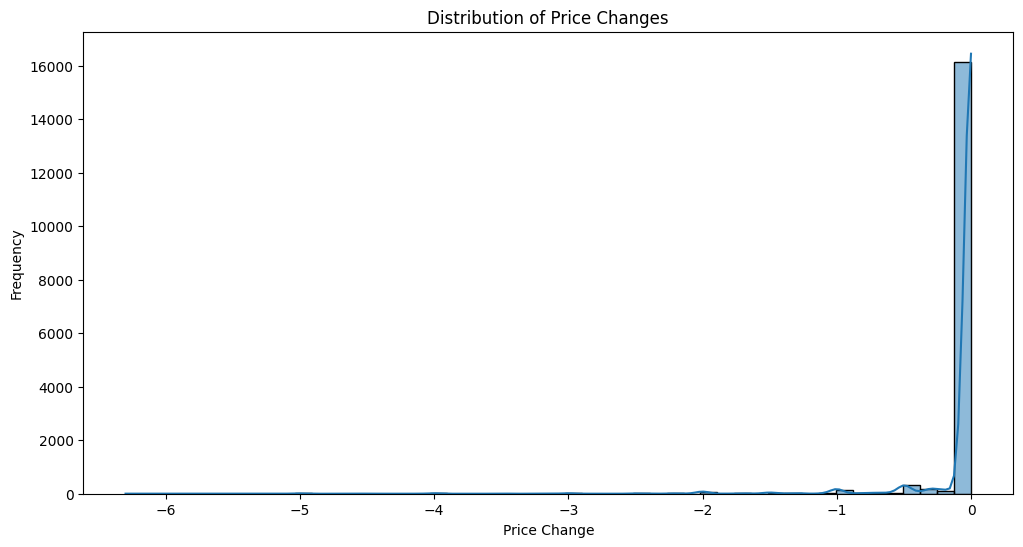

In [ ]:
# Frequency and Magnitude of Price Changes
plt.figure(figsize=(12, 6))
sns.histplot(data['Price Change'], bins=50, kde=True)
plt.title('Distribution of Price Changes')
plt.xlabel('Price Change')
plt.ylabel('Frequency')
plt.show()

In this section, condition check is there. If the absolute value of the 'Price Change' column is greater than 10%  of the 'Current Price' column.
This filters out rows where the price change is not significant (less than 10% of the current price).
It also displays the products that have met the condition for significant price changes, showing their name, current price, previous price, and price change values.


In [ ]:
# Identify products with significant price fluctuations
significant_price_changes = data[data['Price Change'].abs() > 0.1 * data['Current Price']]
print("\nProducts with Significant Price Changes:")
print(significant_price_changes[['Name', 'Current Price', 'Previous Price', 'Price Change']])



Products with Significant Price Changes:
                                                    Name  Current Price  \
11                                              Zucchini           0.92   
15                                         Roma Tomatoes           0.39   
16                                       Broccoli Crowns           1.65   
20     Naturally Imperfect Mixed Sweet Peppers 2.5lb Bag           5.00   
41                                  Yellow Mini Potatoes           2.99   
...                                                  ...            ...   
17056                   Rainbow Cheese Tortellini, Large           6.99   
17075                                  Tortellini, Beef            6.99   
17095                                          Linguine            6.99   
17104                         Ravioli, Cheese & Spinach            6.99   
17197                                Chicken Noodle Soup           6.00   

       Previous Price  Price Change  
11               1.

## To analyze product categorization and identify the most and least popular categories,

It allows visualizing the distribution of products across different categories, providing insights into the number of products in each category. The ordering of the categories based on count helps identify the most and least common categories.

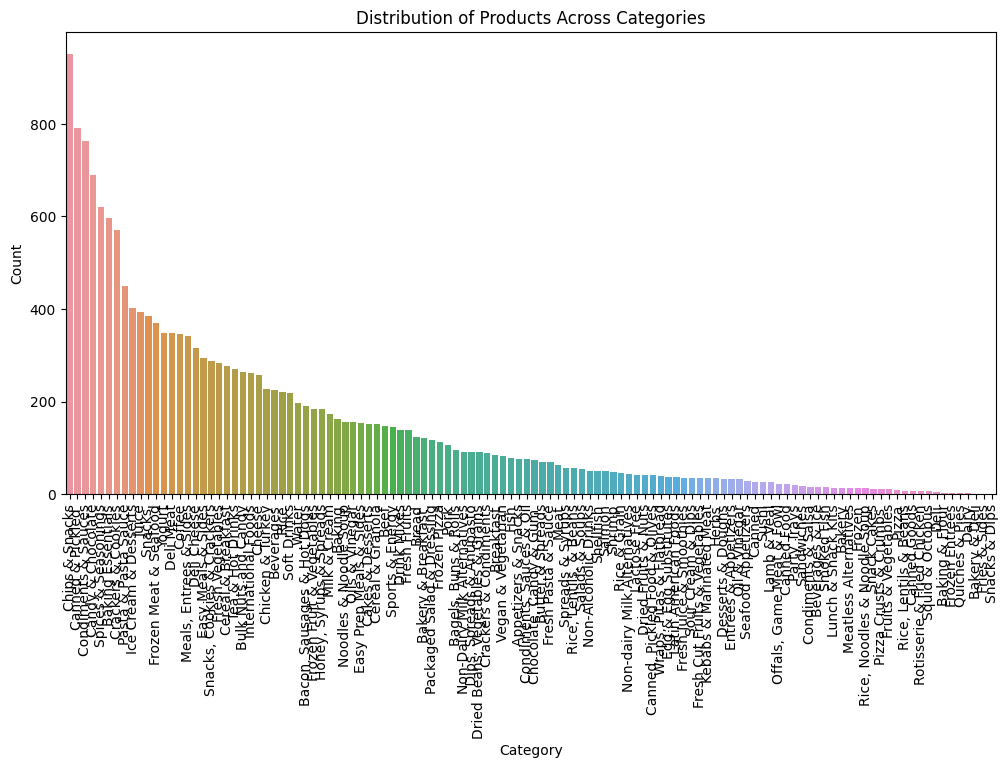

In [ ]:
# Explore the distribution of products across categories
plt.figure(figsize=(12, 6))
sns.countplot(x='Category', data=data, order=data['Category'].value_counts().index)
plt.xticks(rotation=90)
plt.title('Distribution of Products Across Categories')
plt.xlabel('Category')
plt.ylabel('Count')
plt.show()

Here, I identify the most Popular and least popu;ar category

In [ ]:
# Identify the most and least popular categories
category_counts = data['Category'].value_counts()
most_popular_category = category_counts.idxmax()
least_popular_category = category_counts.idxmin()

print("\nMost Popular Category:", most_popular_category)
print("Least Popular Category:", least_popular_category)


Most Popular Category: Chips & Snacks
Least Popular Category: Bakery & Deli


#### Data Cleaning

Here, I find missing values and identify outliers in numeric columns. The isnull() function is used to check for missing values in the dataset.

In [ ]:
missing_values = data.isnull().sum()
outliers = (data[numeric_columns] - data[numeric_columns].mean()).abs() > 3 * data[numeric_columns].std()


Print missing values and outliers

In [ ]:
print("Missing Values:")
print(missing_values)
print("\nOutliers:")
print(outliers)

Missing Values:
Name                  0
Current Price         1
Previous Price        1
Price Per Each    17259
Category              0
Product ID            0
Product URL           0
Amount              884
Units             17259
Price Change          1
dtype: int64

Outliers:
       Current Price  Previous Price  Price Per Each  Amount  Units
0              False           False           False   False  False
1              False           False           False   False  False
2              False           False           False   False  False
3              False           False           False   False  False
4              False           False           False   False  False
...              ...             ...             ...     ...    ...
17254          False           False           False   False  False
17255          False           False           False   False  False
17256          False           False           False   False  False
17257          False           False    

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17259 entries, 0 to 17258
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Name            17259 non-null  object 
 1   Current Price   17258 non-null  float64
 2   Previous Price  17258 non-null  float64
 3   Price Per Each  0 non-null      float64
 4   Category        17259 non-null  object 
 5   Product ID      17259 non-null  object 
 6   Product URL     17259 non-null  object 
 7   Amount          16375 non-null  float64
 8   Units           0 non-null      float64
 9   Price Change    17258 non-null  float64
dtypes: float64(6), object(4)
memory usage: 1.3+ MB


Importaed libraries

In [ ]:
from sklearn.preprocessing import StandardScaler
from scipy.stats import skew

In [ ]:
# Convert relevant columns to numeric types
numeric_columns = ['Current Price', 'Previous Price', 'Price Per Each', 'Amount', 'Units']
data[numeric_columns] = data[numeric_columns].apply(pd.to_numeric, errors='coerce')


Here, I calculate summary statistics and skewness for numeric columns in the dataset

In [ ]:
# Descriptive Statistics
summary_stats = data.describe()
skewness = data[numeric_columns].apply(skew)  # Measure skewness

print("\nDescriptive Statistics:")
print(summary_stats)
print("\nSkewness of Numeric Columns:")
print(skewness)


Descriptive Statistics:
       Current Price  Previous Price  Price Per Each        Amount  Units  \
count   17258.000000    17258.000000             0.0  16375.000000    0.0   
mean        6.948198        7.011918             NaN    295.072220    NaN   
std        10.460156       10.467248             NaN    270.196103    NaN   
min         0.010000        0.180000             NaN      0.077000    NaN   
25%         3.490000        3.490000             NaN     64.000000    NaN   
50%         4.990000        5.000000             NaN    250.000000    NaN   
75%         7.990000        7.990000             NaN    454.000000    NaN   
max       809.990000      809.990000             NaN   5000.000000    NaN   

       Price Change  
count  17258.000000  
mean      -0.063720  
std        0.346013  
min       -6.300000  
25%        0.000000  
50%        0.000000  
75%        0.000000  
max        0.000000  

Skewness of Numeric Columns:
Current Price    NaN
Previous Price   NaN
Price Per E

Here is the code to plot the distribution of the 'Current Price', 'Amount', and 'Units' columns using a histogram with kernel density estimation

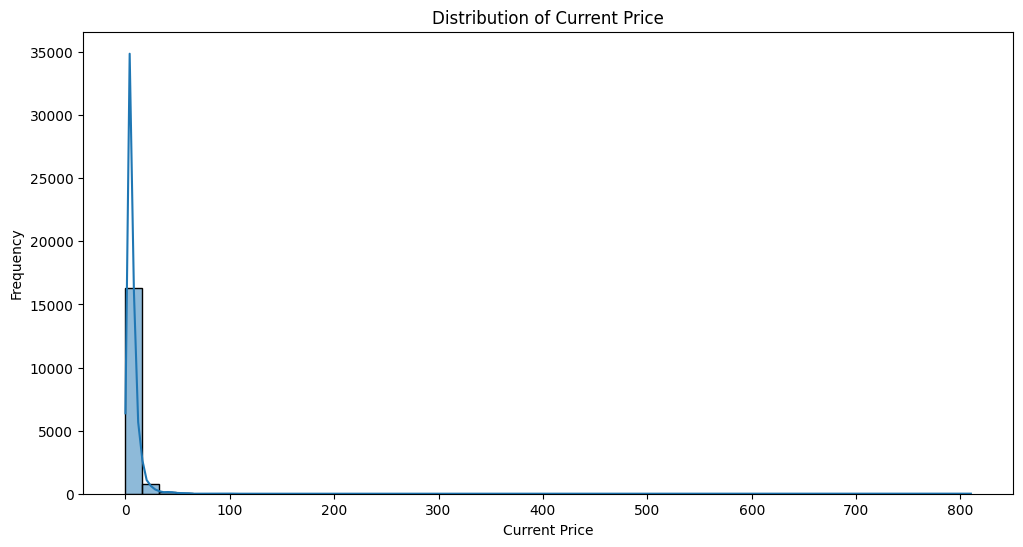

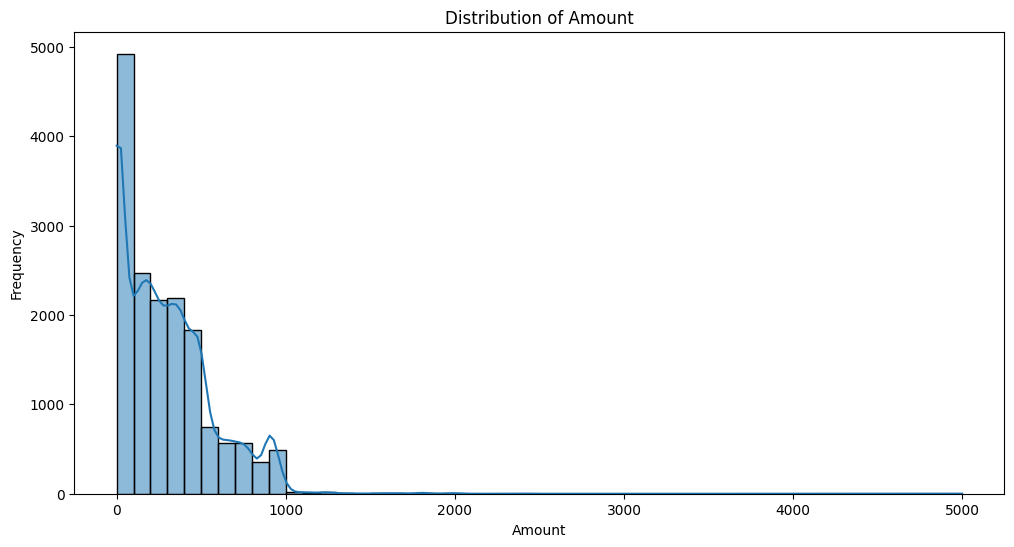

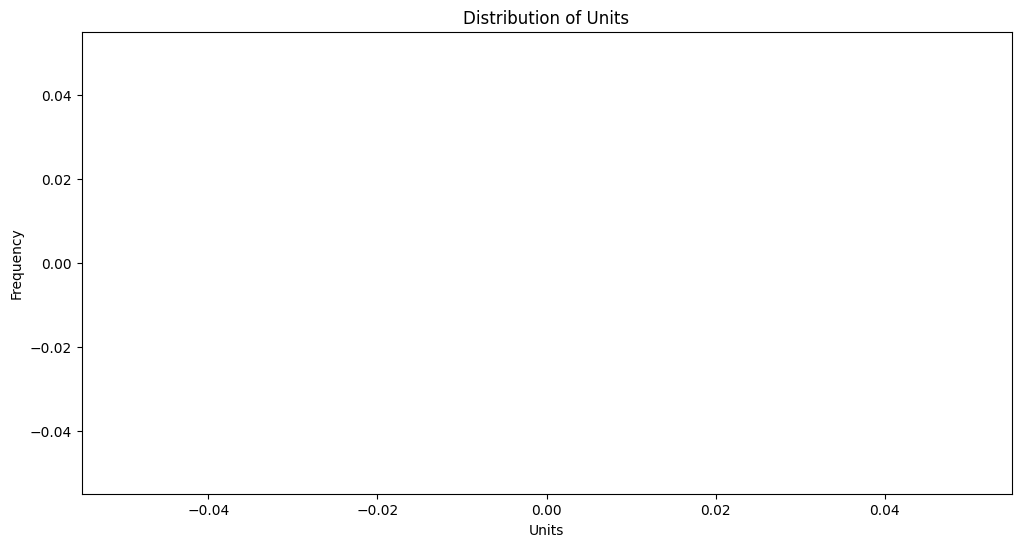

In [ ]:
# Explore the distribution of prices, amounts, and units
for column in ['Current Price', 'Amount', 'Units']:
    plt.figure(figsize=(12, 6))
    sns.histplot(data[column].dropna(), bins=50, kde=True)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()

This code snippet identifies and prints out products with significant price changes in the dataset.

In [ ]:
# Identify products with significant price fluctuations
significant_price_changes = data[data['Price Change'].abs() > 0.1 * data['Current Price']]
print("\nProducts with Significant Price Changes:")
print(significant_price_changes[['Name', 'Category', 'Current Price', 'Previous Price', 'Price Change']])



Products with Significant Price Changes:
                                                    Name             Category  \
11                                              Zucchini     Fresh Vegetables   
15                                         Roma Tomatoes     Fresh Vegetables   
16                                       Broccoli Crowns     Fresh Vegetables   
20     Naturally Imperfect Mixed Sweet Peppers 2.5lb Bag     Fresh Vegetables   
41                                  Yellow Mini Potatoes     Fresh Vegetables   
...                                                  ...                  ...   
17056                   Rainbow Cheese Tortellini, Large  Fresh Pasta & Sauce   
17075                                  Tortellini, Beef   Fresh Pasta & Sauce   
17095                                          Linguine   Fresh Pasta & Sauce   
17104                         Ravioli, Cheese & Spinach   Fresh Pasta & Sauce   
17197                                Chicken Noodle Soup       Sala

This code calculates the average amount sold per category in the dataset and prints the top results.

In [ ]:
# Business Insights
# For example, let's identify categories with the highest average amount sold
average_amount_per_category = data.groupby('Category')['Amount'].mean().sort_values(ascending=False)
print("\nAverage Amount Sold per Category:")
print(average_amount_per_category.head())


Average Amount Sold per Category:
Category
Dairy                      750.000000
Pizza                      740.375000
Non-Alcoholic Drinks       618.894737
Bakery & Deli              600.000000
Fresh Juice & Smoothies    544.671429
Name: Amount, dtype: float64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16034 entries, 0 to 16033
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Name            16034 non-null  object 
 1   Current Price   16034 non-null  object 
 2   Previous Price  16034 non-null  object 
 3   Category        16034 non-null  object 
 4   Product ID      0 non-null      float64
 5   Product URL     16034 non-null  object 
 6   Amount          16034 non-null  object 
dtypes: float64(1), object(6)
memory usage: 877.0+ KB


In [ ]:
# Convert Product ID to numeric if needed
df['Product ID'] = pd.to_numeric(df['Product ID'], errors='coerce')


Removed duplicate rows

In [ ]:
# Remove duplicate rows
df = df.drop_duplicates()


Explored unique values in the 'Category' column

In [ ]:
# Explore unique values in the 'Category' column
unique_categories = df['Category'].unique()


It displays first 5 top rows of the dataset

In [ ]:
df.head()

,Name,Current Price,Previous Price,Category,Product ID,Product URL,Amount
0,English Cucumber,1.99,1.99,Fresh Vegetables,NaN,https://www.realcanadiansuperstore.ca/english-...,1
1,Green Onion,1.29,1.29,Fresh Vegetables,NaN,https://www.realcanadiansuperstore.ca/green-on...,1
2,"Bi-Colour Corn, Corn on the Cob",0.99,0.99,Fresh Vegetables,NaN,https://www.realcanadiansuperstore.ca/bi-colou...,1
3,"Romaine Heart, 3 Pack",6.00,6.00,Fresh Vegetables,NaN,https://www.realcanadiansuperstore.ca/romaine-...,3
4,Red Peppers,2.38,2.38,Fresh Vegetables,NaN,https://www.realcanadiansuperstore.ca/red-pepp...,1


In [ ]:
df.columns

Index(['Name', 'Current Price', 'Previous Price', 'Category', 'Product ID',
       'Product URL', 'Amount'],
      dtype='object')

Here, I take 'Current Price' as the Target variable. Dropped irrelevant columns like 'Name', 'Product ID', 'Product URL'. Separate features (X) and target variable (y). Split the data into training and testing sets. 20% of the data will be used for testing. The resulting variables X_train, X_test, y_train, and y_test contain the respective splits of the dataset for training and testing purposes. These pipelines define the necessary data transformations to handle missing values and scale/encode the features appropriately, depending on their data types. 4.	The performance of the model is evaluated using various metrics. In this case, the mean squared error (mse), mean absolute error (mae), R-squared score (r2), and explained variance score (evs) are calculated by comparing the predicted values (y_pred) with the actual values (y_test).

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Load your data
# Assuming df is your DataFrame
# Drop irrelevant columns like 'Name', 'Product ID', 'Product URL'
df = df.drop(['Name', 'Product ID', 'Product URL'], axis=1)

# Convert 'Current Price' to numeric
df['Current Price'] = pd.to_numeric(df['Current Price'], errors='coerce')

# Drop rows with NaN values in the target variable
df = df.dropna(subset=['Current Price'])

# Separate features (X) and target variable (y)
X = df.drop('Current Price', axis=1)
y = df['Current Price']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define numerical and categorical features
numerical_features = X.select_dtypes(include=['float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

# Create transformers for numerical and categorical features
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine transformers into a preprocessor using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Models
models = [
    ('Linear Regression', LinearRegression()),
    ('Random Forest Regressor', RandomForestRegressor(n_estimators=100, random_state=42)),
    ('Support Vector Regressor', SVR()),
    ('Gradient Boosting Regressor', GradientBoostingRegressor(n_estimators=100, random_state=42))
]

# Iterate over models
for model_name, model in models:
    # Create the full pipeline with the preprocessor and the current model
    model_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                      ('regressor', model)])

    # Fit the model
    model_pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = model_pipeline.predict(X_test)

    # Evaluate the model
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    evs = explained_variance_score(y_test, y_pred)

    print(f'{model_name} Evaluation Metrics:')
    print(f'Mean Squared Error (MSE): {mse}')
    print(f'Mean Absolute Error (MAE): {mae}')
    print(f'R-squared (R2): {r2}')
    print(f'Explained Variance Score (EVS): {evs}')
    print('-' * 30)


Linear Regression Evaluation Metrics:
Mean Squared Error (MSE): 124.5799299596785
Mean Absolute Error (MAE): 0.6410783088394435
R-squared (R2): 0.48822757887579515
Explained Variance Score (EVS): 0.4885705237682594
------------------------------
Random Forest Regressor Evaluation Metrics:
Mean Squared Error (MSE): 154.36100610180475
Mean Absolute Error (MAE): 0.9506318945538874
R-squared (R2): 0.3658873797291654
Explained Variance Score (EVS): 0.3676741343751433
------------------------------
Support Vector Regressor Evaluation Metrics:
Mean Squared Error (MSE): 219.7452007888466
Mean Absolute Error (MAE): 1.6637456977379956
R-squared (R2): 0.09729012149443994
Explained Variance Score (EVS): 0.10271326788850088
------------------------------
Gradient Boosting Regressor Evaluation Metrics:
Mean Squared Error (MSE): 153.23664942330132
Mean Absolute Error (MAE): 3.0948612512000104
R-squared (R2): 0.3705062195354738
Explained Variance Score (EVS): 0.37100862672209156
----------------------